In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load interaction dataset
interaction_path = Path("../data/interaction/user_interactions.csv")

interactions_df = pd.read_csv(interaction_path)

# Display first five records
display(interactions_df.head())

# Display dataset information
print("Dataset Shape:", interactions_df.shape)

print("\nColumn Names:")
print(interactions_df.columns.tolist())

print("\nDataset Information:")
interactions_df.info()

,user_id,talk_id,title,rating,like_status,watched,saved
0,USER_001,TALK_001,Al Gore sobre cómo evitar la crisis climática,2,Dislike,True,True
1,USER_001,TALK_005,Hans Rosling nos muestra las mejores estadísti...,5,Like,True,True
2,USER_001,TALK_004,Ken Robinson dice que las escuelas matan la cr...,5,Like,True,False
3,USER_001,TALK_002,"David Pogue dice ""La Simplicidad Vende""",1,Dislike,True,True
4,USER_002,TALK_004,Ken Robinson dice que las escuelas matan la cr...,2,Dislike,True,False


Dataset Shape: (43, 7)

Column Names:
['user_id', 'talk_id', 'title', 'rating', 'like_status', 'watched', 'saved']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      43 non-null     str  
 1   talk_id      43 non-null     str  
 2   title        43 non-null     str  
 3   rating       43 non-null     int64
 4   like_status  43 non-null     str  
 5   watched      43 non-null     bool 
 6   saved        43 non-null     bool 
dtypes: bool(2), int64(1), str(4)
memory usage: 1.9 KB


In [3]:
# Standardize column names
interactions_df.columns = (
    interactions_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Detect important columns
column_mapping = {
    "user": ["user_id", "userid"],
    "talk": ["talk_id", "ted_talk_id", "tedtalk_id"],
    "rating": ["rating", "user_rating"]
}

def find_column(possible_names):
    for col in possible_names:
        if col in interactions_df.columns:
            return col
    return None

user_col = find_column(column_mapping["user"])
talk_col = find_column(column_mapping["talk"])
rating_col = find_column(column_mapping["rating"])

if not all([user_col, talk_col, rating_col]):
    raise ValueError(
        "Required columns not found. Check your Task 7 dataset."
    )

# Rename columns
interactions_df = interactions_df.rename(columns={
    user_col: "user_id",
    talk_col: "talk_id",
    rating_col: "rating"
})

# Remove missing essential values
interactions_df = interactions_df.dropna(
    subset=["user_id", "talk_id", "rating"]
).copy()

# Convert IDs to strings
interactions_df["user_id"] = interactions_df["user_id"].astype(str)
interactions_df["talk_id"] = interactions_df["talk_id"].astype(str)

# Convert ratings to numeric
interactions_df["rating"] = pd.to_numeric(
    interactions_df["rating"], errors="coerce"
)

interactions_df = interactions_df.dropna(subset=["rating"])

# Handle duplicate user-talk interactions
interactions_df = (
    interactions_df
    .groupby(["user_id", "talk_id"], as_index=False)
    ["rating"].mean()
)

print("Dataset prepared successfully!")

display(interactions_df.head())

Dataset prepared successfully!


,user_id,talk_id,rating
0,USER_001,TALK_001,2.0
1,USER_001,TALK_002,1.0
2,USER_001,TALK_004,5.0
3,USER_001,TALK_005,5.0
4,USER_002,TALK_001,5.0


In [4]:
# Create User-Item Matrix
user_item_matrix = interactions_df.pivot(
    index="user_id",
    columns="talk_id",
    values="rating"
)

print("User-Item Interaction Matrix:")

display(user_item_matrix)

User-Item Interaction Matrix:


talk_id,TALK_001,TALK_002,TALK_003,TALK_004,TALK_005,TALK_006,TALK_007,TALK_008,TALK_009,TALK_010
user_id,,,,,,,,,,
USER_001,2.0,1.0,NaN,5.0,5.0,NaN,NaN,NaN,NaN,NaN
USER_002,5.0,NaN,NaN,2.0,1.0,NaN,NaN,NaN,NaN,2.0
USER_003,4.0,1.0,5.0,NaN,3.0,4.0,NaN,5.0,5.0,NaN
USER_004,4.0,4.0,NaN,2.0,NaN,2.0,NaN,3.0,NaN,3.0
USER_005,NaN,3.0,3.0,2.0,NaN,2.0,NaN,3.0,NaN,3.0
USER_006,NaN,5.0,3.0,NaN,NaN,NaN,5.0,2.0,NaN,5.0
USER_007,5.0,5.0,NaN,NaN,NaN,NaN,4.0,2.0,1.0,NaN
USER_008,3.0,2.0,5.0,NaN,5.0,1.0,NaN,NaN,3.0,NaN


In [5]:
# Save User-Item Matrix
output_path = Path("../data/interaction/user_item_matrix.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

user_item_matrix.to_csv(output_path)

print("User-Item Matrix saved successfully!")

User-Item Matrix saved successfully!


In [6]:
# Fill missing ratings with zero
user_item_filled = user_item_matrix.fillna(0)

print("User-Item Matrix after filling missing values:")

display(user_item_filled)

User-Item Matrix after filling missing values:


talk_id,TALK_001,TALK_002,TALK_003,TALK_004,TALK_005,TALK_006,TALK_007,TALK_008,TALK_009,TALK_010
user_id,,,,,,,,,,
USER_001,2.0,1.0,0.0,5.0,5.0,0.0,0.0,0.0,0.0,0.0
USER_002,5.0,0.0,0.0,2.0,1.0,0.0,0.0,0.0,0.0,2.0
USER_003,4.0,1.0,5.0,0.0,3.0,4.0,0.0,5.0,5.0,0.0
USER_004,4.0,4.0,0.0,2.0,0.0,2.0,0.0,3.0,0.0,3.0
USER_005,0.0,3.0,3.0,2.0,0.0,2.0,0.0,3.0,0.0,3.0
USER_006,0.0,5.0,3.0,0.0,0.0,0.0,5.0,2.0,0.0,5.0
USER_007,5.0,5.0,0.0,0.0,0.0,0.0,4.0,2.0,1.0,0.0
USER_008,3.0,2.0,5.0,0.0,5.0,1.0,0.0,0.0,3.0,0.0


In [7]:
# Calculate cosine similarity
similarity_values = cosine_similarity(user_item_filled)

# Create User Similarity Matrix
user_similarity_matrix = pd.DataFrame(
    similarity_values,
    index=user_item_filled.index,
    columns=user_item_filled.index
)

print("User Similarity Matrix:")

display(user_similarity_matrix.round(3))

User Similarity Matrix:


user_id,USER_001,USER_002,USER_003,USER_004,USER_005,USER_006,USER_007,USER_008
user_id,,,,,,,,
USER_001,1.000,0.578,0.299,0.390,0.264,0.072,0.240,0.521
USER_002,0.578,1.000,0.365,0.676,0.259,0.183,0.509,0.401
USER_003,0.299,0.365,1.000,0.522,0.571,0.296,0.439,0.790
USER_004,0.390,0.676,0.522,1.000,0.752,0.574,0.717,0.338
USER_005,0.264,0.259,0.571,0.752,1.000,0.723,0.376,0.406
USER_006,0.072,0.183,0.296,0.574,0.723,1.000,0.620,0.312
USER_007,0.240,0.509,0.439,0.717,0.376,0.620,1.000,0.389
USER_008,0.521,0.401,0.790,0.338,0.406,0.312,0.389,1.000


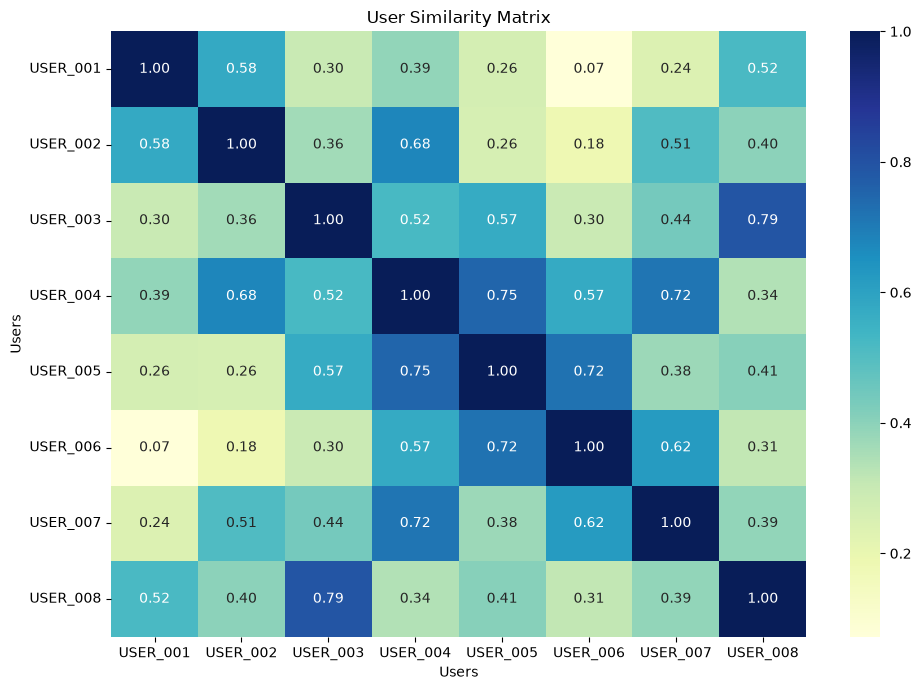

In [8]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    user_similarity_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("User Similarity Matrix")
plt.xlabel("Users")
plt.ylabel("Users")

plt.tight_layout()
plt.show()

In [9]:
# Select a user
selected_user = user_similarity_matrix.index[0]

# Get similarity scores
similar_users = user_similarity_matrix[selected_user].drop(
    selected_user
)

# Sort users by similarity
similar_users = similar_users.sort_values(
    ascending=False
)

print("Selected User:", selected_user)

print("\nMost Similar Users:")

display(similar_users.head(5))

Selected User: USER_001

Most Similar Users:


user_id
USER_002    0.578122
USER_008    0.520800
USER_004    0.389518
USER_003    0.299183
USER_005    0.264263
Name: USER_001, dtype: float64

In [10]:
def recommend_for_user(user_id, top_n=5):

    # Check whether user exists
    if user_id not in user_item_filled.index:
        print("Invalid User ID:", user_id)
        return pd.DataFrame()

    # Get similarity scores
    similar_users = user_similarity_matrix[user_id].drop(user_id)

    # Sort similar users
    similar_users = similar_users.sort_values(
        ascending=False
    )

    # Keep users with positive similarity
    similar_users = similar_users[similar_users > 0]

    if similar_users.empty:
        print("No similar users found.")
        return pd.DataFrame()

    # Find talks not rated by selected user
    unrated_talks = user_item_matrix.loc[user_id][
        user_item_matrix.loc[user_id].isna()
    ].index

    recommendations = []

    # Calculate predicted rating
    for talk_id in unrated_talks:

        # Get ratings from similar users
        ratings = user_item_matrix.loc[
            similar_users.index, talk_id
        ]

        # Remove missing ratings
        valid_ratings = ratings.dropna()

        if valid_ratings.empty:
            continue

        # Get similarity scores of users who rated the talk
        weights = similar_users.loc[valid_ratings.index]

        if weights.sum() == 0:
            continue

        # Weighted average rating
        predicted_rating = np.average(
            valid_ratings,
            weights=weights
        )

        recommendations.append({
            "TED_Talk_ID": talk_id,
            "Predicted_Rating": round(predicted_rating, 3)
        })

    # Create recommendation DataFrame
    recommendation_df = pd.DataFrame(recommendations)

    if recommendation_df.empty:
        print("No recommendations available.")
        return recommendation_df

    # Sort by predicted rating
    recommendation_df = recommendation_df.sort_values(
        by="Predicted_Rating",
        ascending=False
    )

    return recommendation_df.head(top_n).reset_index(drop=True)

In [11]:
# Select three users
test_users = user_item_filled.index[:3].tolist()

for user in test_users:

    print("\n================================")
    print("Recommendations for:", user)
    print("================================")

    result = recommend_for_user(user, top_n=5)

    display(result)


Recommendations for: USER_001


,TED_Talk_ID,Predicted_Rating
0,TALK_003,4.419
1,TALK_007,4.230
2,TALK_008,3.226
3,TALK_009,3.112
4,TALK_010,2.667



Recommendations for: USER_002


,TED_Talk_ID,Predicted_Rating
0,TALK_003,4.269
1,TALK_007,4.264
2,TALK_008,3.019
3,TALK_002,2.923
4,TALK_009,2.774



Recommendations for: USER_003


,TED_Talk_ID,Predicted_Rating
0,TALK_007,4.403
1,TALK_010,3.129
2,TALK_004,2.511


In [12]:
invalid_result = recommend_for_user(
    "USER_999",
    top_n=5
)

Invalid User ID: USER_999


In [13]:
for user in test_users:

    result = recommend_for_user(user, top_n=5)

    if not result.empty:

        # Check already-rated talks
        rated_talks = set(
            user_item_matrix.loc[user].dropna().index
        )

        recommended_talks = set(result["TED_Talk_ID"])

        assert rated_talks.isdisjoint(recommended_talks), (
            "Already-rated talks found!"
        )

        # Check descending order
        assert result["Predicted_Rating"].is_monotonic_decreasing

        print(user, "- Verification successful!")

print("\nAll recommendation checks completed.")

USER_001 - Verification successful!
USER_002 - Verification successful!
USER_003 - Verification successful!

All recommendation checks completed.


In [17]:
# Load original cleaned TED Talks dataset
talks_path = Path("../data/processed/ted_talks_cleaned.csv")

talks_df = pd.read_csv("C:\\Users\\bhava\\OneDrive\\Desktop\\TED TALKS RECOMMADATION\\data\\interaction\\user_interactions.csv")

print("TED Talks Dataset Columns:")
print(talks_df.columns.tolist())

TED Talks Dataset Columns:
['user_id', 'talk_id', 'title', 'rating', 'like_status', 'watched', 'saved']


In [18]:
# Detect title column
possible_title_columns = [
    "title", "Title", "talk_title",
    "Talk Title", "name", "Name"
]

title_col = next(
    (col for col in possible_title_columns
     if col in talks_df.columns),
    None
)

# Detect an existing ID column
possible_id_columns = [
    "talk_id", "TED_Talk_ID", "ted_talk_id",
    "id", "ID"
]

talk_id_col = next(
    (col for col in possible_id_columns
     if col in talks_df.columns),
    None
)

# Prefer title information already stored in Task 7
interaction_title_col = next(
    (col for col in interactions_df.columns
     if col.lower() in [
         "title", "talk_title", "ted_talk_title"
     ]),
    None
)

if interaction_title_col is not None:

    title_mapping = (
        interactions_df
        .dropna(subset=[interaction_title_col])
        .drop_duplicates("talk_id")
        .set_index("talk_id")[interaction_title_col]
    )

elif title_col is not None and talk_id_col is not None:

    talks_df[talk_id_col] = talks_df[talk_id_col].astype(str)

    title_mapping = (
        talks_df
        .dropna(subset=[title_col])
        .drop_duplicates(talk_id_col)
        .set_index(talk_id_col)[title_col]
    )

else:
    title_mapping = pd.Series(dtype="object")

print("Title mapping prepared.")

Title mapping prepared.


In [19]:
# Display recommendations with titles
for user in test_users:

    print("\nRecommendations for", user)

    result = recommend_for_user(user, top_n=5)

    if not result.empty:

        result["TED_Talk_Title"] = (
            result["TED_Talk_ID"]
            .map(title_mapping)
            .fillna("Title not found - check Talk ID mapping")
        )

        display(
            result[
                [
                    "TED_Talk_ID",
                    "TED_Talk_Title",
                    "Predicted_Rating"
                ]
            ]
        )


Recommendations for USER_001


,TED_Talk_ID,TED_Talk_Title,Predicted_Rating
0,TALK_003,Un recorrido por la renovación urbana de la ma...,4.419
1,TALK_007,Joshua Prince-Ramus habla sobre la biblioteca ...,4.230
2,TALK_008,Dan Dennett responde a Rick Warren,3.226
3,TALK_009,Rick Warren acerca de una vida con propósito.,3.112
4,TALK_010,Jehane Noujaim inspira un día mundial de cine,2.667



Recommendations for USER_002


,TED_Talk_ID,TED_Talk_Title,Predicted_Rating
0,TALK_003,Un recorrido por la renovación urbana de la ma...,4.269
1,TALK_007,Joshua Prince-Ramus habla sobre la biblioteca ...,4.264
2,TALK_008,Dan Dennett responde a Rick Warren,3.019
3,TALK_002,"David Pogue dice ""La Simplicidad Vende""",2.923
4,TALK_009,Rick Warren acerca de una vida con propósito.,2.774



Recommendations for USER_003


,TED_Talk_ID,TED_Talk_Title,Predicted_Rating
0,TALK_007,Joshua Prince-Ramus habla sobre la biblioteca ...,4.403
1,TALK_010,Jehane Noujaim inspira un día mundial de cine,3.129
2,TALK_004,Ken Robinson dice que las escuelas matan la cr...,2.511


In [20]:
# Preserve TED Talk titles before grouping
title_col_interaction = next(
    (
        col for col in interactions_df.columns
        if col in ["title", "talk_title", "ted_talk_title"]
    ),
    None
)

if title_col_interaction:
    title_mapping = (
        interactions_df
        .dropna(subset=[title_col_interaction])
        .drop_duplicates("talk_id")
        .set_index("talk_id")[title_col_interaction]
    )
else:
    title_mapping = pd.Series(dtype="object")

In [21]:
print("Missing Values:")
print(interactions_df.isnull().sum())

print("\nDuplicate Records:")
print(interactions_df.duplicated().sum())

print("\nUnique Users:")
print(interactions_df.iloc[:, 0].nunique())

Missing Values:
user_id    0
talk_id    0
rating     0
dtype: int64

Duplicate Records:
0

Unique Users:
8
